# Process All Segment-wise Correlation Matrices

This notebook imports the segment-wise correlation matrices for all subjects, sessions, and segments, and computes their absolute values.

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from collections import defaultdict

# Define the base directory where the segment-wise correlation matrices are stored
data_dir = './correlation_matrices_segment_wise_(notAbsolute)'

# Find all CSV files recursively for all subjects and sessions
file_paths = sorted(glob.glob(os.path.join(data_dir, 'sub-*', 'ses-*', '*_pearson_corr.csv')))
print(f"Found {len(file_paths)} correlation matrices across all subjects.")

In [ ]:
# Nested dictionary to store the original matrices: corr_matrices[subject][session][segment]
corr_matrices = defaultdict(lambda: defaultdict(dict))

for path in file_paths:
    # Extract subject, session, and segment from the file name
    filename = os.path.basename(path)
    parts = filename.split('_')
    
    if len(parts) >= 3:
        subject = parts[0]   # e.g., 'sub-NORB00001'
        session = parts[1]   # e.g., 'ses-1'
        segment = parts[2]   # e.g., 'segment-01'
    else:
        continue
    
    # Read the CSV file into a pandas DataFrame.
    df = pd.read_csv(path, index_col=0)
    
    # Store the original matrix in our nested dictionary
    corr_matrices[subject][session][segment] = df

# Convert defaultdict back to a regular dict for standard usage
corr_matrices = {k: {sk: dict(sv) for sk, sv in v.items()} for k, v in corr_matrices.items()}

print(f"Successfully imported matrices for {len(corr_matrices)} subjects.")

In [ ]:
# Create a separate nested dictionary for the absolute correlation matrices
abs_corr_matrices = defaultdict(lambda: defaultdict(dict))

for subject in corr_matrices:
    for session in corr_matrices[subject]:
        for segment in corr_matrices[subject][session]:
            # Take the absolute value (modulus) of all correlation values
            abs_corr_matrices[subject][session][segment] = corr_matrices[subject][session][segment].abs()

abs_corr_matrices = {k: {sk: dict(sv) for sk, sv in v.items()} for k, v in abs_corr_matrices.items()}

print("Successfully computed absolute values for all correlation matrices.")

In [ ]:
# Example: Show the absolute correlation matrix for the first available subject, session, and segment
if abs_corr_matrices:
    sample_sub = list(abs_corr_matrices.keys())[0]
    sample_ses = list(abs_corr_matrices[sample_sub].keys())[0]
    sample_seg = list(abs_corr_matrices[sample_sub][sample_ses].keys())[0]

    print(f"Displaying matrix for {sample_sub}, {sample_ses}, {sample_seg}:")
    display(abs_corr_matrices[sample_sub][sample_ses][sample_seg].head())
else:
    print("No matrices found.")

## Compute Pair-wise Jaccard Matrices for Session 1

Here we find all subjects with multiple sessions (excluding `sub-NORB00074`), and for `ses-1`, we compute the node-pair-wise Jaccard matrix between pairs of subjects for a specified number of segments.
The node-pair wise Jaccard index is calculated as `min(A, B) / max(A, B)` for every individual node pair.

In [ ]:
import itertools

# Variable for number of segments to process (can be changed)
num_segments = 8

# 1. Identify subjects with multiple sessions
subjects_with_multiple_sessions = []
for subject, sessions in abs_corr_matrices.items():
    if len(sessions) > 1:
        subjects_with_multiple_sessions.append(subject)

# 2. Exclude sub-NORB00074 as requested
excluded_subjects = ['sub-NORB00074']
filtered_subjects = [sub for sub in subjects_with_multiple_sessions if sub not in excluded_subjects]

print(f"Found {len(filtered_subjects)} subjects with multiple sessions (excluding sub-NORB00074).")

# Dictionary to store Jaccard matrices
# jaccard_results[segment][(sub_x, sub_y)] = jaccard_matrix_dataframe
jaccard_results = defaultdict(dict)

def pairwise_jaccard_matrix(mat1, mat2):
    """
    Calculates the Jaccard index for each node pair using the min(A, B) / max(A, B) approach.
    Returns a pandas DataFrame of the exact same shape.
    """
    min_mat = np.minimum(mat1, mat2)
    max_mat = np.maximum(mat1, mat2)
    
    # Divide min by max. If max is 0 (meaning both are 0), 
    # replace with NaN temporarily to avoid division by zero error.
    jaccard_mat = min_mat.div(max_mat.replace(0, np.nan))
    
    # Fill NaN values (which occurred where both A and B were exactly 0) with 0.0
    jaccard_mat = jaccard_mat.fillna(0.0)
    
    return jaccard_mat

# Generate the segment keys: 'segment-01', 'segment-02', etc.
segment_keys = [f"segment-{str(i).zfill(2)}" for i in range(1, num_segments + 1)]

# 3. Calculate Jaccard matrices for 'ses-1' across pairs
session_id = 'ses-1'

for segment in segment_keys:
    # Get all unique pairs of the filtered subjects
    for sub_x, sub_y in itertools.combinations(filtered_subjects, 2):
        
        # Make sure both subjects have 'ses-1' and the specific segment
        if (session_id in abs_corr_matrices[sub_x] and segment in abs_corr_matrices[sub_x][session_id] and
            session_id in abs_corr_matrices[sub_y] and segment in abs_corr_matrices[sub_y][session_id]):
            
            mat_x = abs_corr_matrices[sub_x][session_id][segment]
            mat_y = abs_corr_matrices[sub_y][session_id][segment]
            
            j_matrix = pairwise_jaccard_matrix(mat_x, mat_y)
            jaccard_results[segment][(sub_x, sub_y)] = j_matrix
            
# Convert to regular dict for standard usage
jaccard_results = {k: dict(v) for k, v in jaccard_results.items()}

print(f"Calculated node-pair Jaccard matrices for {len(jaccard_results)} segments.")

In [ ]:
# Display an example of the computed Jaccard Index DataFrame for a subject pair with a heatmap
import seaborn as sns
import matplotlib.pyplot as plt

if jaccard_results:
    first_segment = list(jaccard_results.keys())[0]
    if jaccard_results[first_segment]:
        sample_pair = list(jaccard_results[first_segment].keys())[0]
        print(f"Example Node-Pair Jaccard Matrix")
        print(f"Segment: {first_segment}")
        print(f"Subject Pair: {sample_pair[0]} and {sample_pair[1]}")
        
        # Display the dataframe
        df_example = jaccard_results[first_segment][sample_pair]
        display(df_example.head())
        
        # Plot the heatmap
        plt.figure(figsize=(10, 8))
        sns.heatmap(df_example, annot=False, cmap='viridis', vmin=0, vmax=1)
        plt.title(f"Jaccard Matrix Heatmap\n{sample_pair[0]} vs {sample_pair[1]} ({first_segment})")
        plt.tight_layout()
        plt.show()
else:
    print("No Jaccard matrices found to display.")

## Average Jaccard Matrices Across Segments

Here we aggregate the Jaccard matrices. For each subject pair, we take all the segment matrices (e.g., 8 segments) and compute the average matrix.

In [ ]:
# Dictionary to store the averaged Jaccard matrix for each subject pair
# average_jaccard_results[(sub_x, sub_y)] = average_matrix_dataframe
average_jaccard_results = {}

# We will iterate over all subject pairs found in the first segment
if jaccard_results and segment_keys[0] in jaccard_results:
    subject_pairs = list(jaccard_results[segment_keys[0]].keys())
    
    for pair in subject_pairs:
        # Collect all available segment matrices for this pair
        matrices_for_pair = []
        for segment in segment_keys:
            if segment in jaccard_results and pair in jaccard_results[segment]:
                matrices_for_pair.append(jaccard_results[segment][pair])
        
        # Calculate the element-wise average matrix if we have any matrices
        if matrices_for_pair:
            # Sum all dataframes and divide by count
            sum_matrix = sum(matrices_for_pair)
            avg_matrix = sum_matrix / len(matrices_for_pair)
            
            average_jaccard_results[pair] = avg_matrix

    print(f"Calculated average Jaccard matrix for {len(average_jaccard_results)} subject pairs.")
    
    # --- Show an example of the averaged matrix and its heatmap ---
    sample_pair = subject_pairs[0]
    print(f"\nExample Averaged Jaccard Matrix for {sample_pair[0]} and {sample_pair[1]}")
    print(f"(Averaged over {len(matrices_for_pair)} segments)")
    
    df_avg_example = average_jaccard_results[sample_pair]
    display(df_avg_example.head())
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(df_avg_example, annot=False, cmap='viridis', vmin=0, vmax=1)
    plt.title(f"Averaged Jaccard Matrix Heatmap\n{sample_pair[0]} vs {sample_pair[1]}")
    plt.tight_layout()
    plt.show()

else:
    print("No Jaccard results found to average.")

## Comprehensive Heatmap for All Subject Pairs

Here we create a large heatmap where columns represent the individual edge pairs and rows represent the subject pairs. The values are the averaged Jaccard similarities.

The columns are grouped exactly by node region combinations (FF, FC, FT, FP, FO, CC, CT, CP, CO, TT, TP, TO, PP, PO, OO).
The rows (subject pairs) are sorted by their age difference (from highest difference at the top to lowest difference at the bottom).

In [ ]:
# Extract all unique edge pairs from the first averaged matrix
if average_jaccard_results:
    first_avg_mat = list(average_jaccard_results.values())[0]
    
    # Get all combinations of electrodes (columns of the dataframe)
    nodes = list(first_avg_mat.columns)
    edge_pairs = list(itertools.combinations(nodes, 2))
    
    # --- Sort the edge pairs by band order ---
    # The requested order groups by regions: FF, FC, FT, FP, FO, CC, CT, CP, CO, TT, TP, TO, PP, PO, OO
    band_order = 'FCTPO'
    order_keys = [a + b for i, a in enumerate(band_order) for b in band_order[i:]]
    order_map = {k: i for i, k in enumerate(order_keys)}
    
    def band_key(edge):
        a, b = edge
        # The first character of the electrode name determines its region (e.g., 'Fp1' -> 'F')
        return ''.join(sorted((a[0].upper(), b[0].upper()), key=lambda c: band_order.index(c)))
    
    sorted_edge_pairs = sorted(edge_pairs, key=lambda ep: order_map[band_key(ep)])
    edge_labels = [f"{a}-{b}" for a, b in sorted_edge_pairs]
    
    heatmap_rows = []
    heatmap_indices = []
    
    # --- Sort subject pairs by age difference ---
    try:
        age_df = pd.read_csv('age_acq_time_sorted.csv')
        age_lookup = dict(zip(age_df['label'], age_df['age_acq_time']))
    except FileNotFoundError:
        print("Warning: age_acq_time_sorted.csv not found, proceeding without age sorting.")
        age_lookup = {}
        
    pair_age_diffs = []
    for pair in average_jaccard_results.keys():
        sub1_label = f"{pair[0]}_ses-1"
        sub2_label = f"{pair[1]}_ses-1"
        
        if sub1_label in age_lookup and sub2_label in age_lookup:
            age_diff = abs(age_lookup[sub1_label] - age_lookup[sub2_label])
        else:
            age_diff = float('inf')
            
        pair_age_diffs.append({'pair': pair, 'age_diff': age_diff})
        
    # Sort descending so the least age difference is at the bottom of the heatmap
    sorted_pair_dicts = sorted(pair_age_diffs, key=lambda x: x['age_diff'], reverse=True)
    
    for pair_dict in sorted_pair_dicts:
        pair = pair_dict['pair']
        age_diff = pair_dict['age_diff']
        avg_mat = average_jaccard_results[pair]
        
        # Extract the Jaccard index for each sorted edge pair
        row_values = []
        for a, b in sorted_edge_pairs:
            if a in avg_mat.index and b in avg_mat.columns:
                val = avg_mat.loc[a, b]
                row_values.append(val)
            else:
                row_values.append(np.nan)
                
        heatmap_rows.append(row_values)
        
        # Add age diff to the label for clarity
        if age_diff != float('inf'):
            heatmap_indices.append(f"{pair[0]} vs {pair[1]} (Diff: {age_diff:.4f})")
        else:
            heatmap_indices.append(f"{pair[0]} vs {pair[1]}")
        
    heatmap_df = pd.DataFrame(
        heatmap_rows,
        index=heatmap_indices,
        columns=edge_labels
    )
    
    print(f"\nHeatmap shape: {heatmap_df.shape}")
    print(f"Valid subject pairs used: {len(heatmap_df)}")
    
    if not heatmap_df.empty:
        # Dimensions based on the reference notebook style
        fig_width = max(72, len(heatmap_df.columns) * 0.45)
        fig_height = max(18, len(heatmap_df.index) * 0.14)
        
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))
        sns.heatmap(
            heatmap_df,
            cmap='hot',
            cbar_kws={'label': 'Jaccard Index'},
            vmin=0,
            vmax=1,
            ax=ax,
            xticklabels=False,
            yticklabels=True,
        )
        
        ax.set_xticks(np.arange(len(heatmap_df.columns)) + 0.5)
        ax.set_xticklabels(heatmap_df.columns, rotation=90, fontsize=4)
        ax.tick_params(axis='x', which='both', length=2, pad=1)
        
        # --- Draw vertical lines separating the band groups ---
        col_band_keys = [band_key(ep) for ep in sorted_edge_pairs]
        unique_band_keys = [k for k in order_keys if k in col_band_keys]
        
        for key in unique_band_keys:
            indices = [i for i, k in enumerate(col_band_keys) if k == key]
            if indices:
                # Add a vertical line at the start of each group
                start_idx = indices[0]
                ax.axvline(x=start_idx, color='cyan', linestyle='-', linewidth=2, alpha=0.7)
                
                # Add text label for the group right above the chart
                ax.text(start_idx + len(indices)/2, -0.5, key, 
                        ha='center', va='bottom', color='cyan', fontsize=12, fontweight='bold')
        
        plt.title("Averaged Jaccard Index Heatmap for all Subject Pairs (Sorted by Age Difference)", fontsize=24, pad=20)
        plt.tight_layout()
        plt.show()
else:
    print("No averaged Jaccard matrices available to plot.")

## Compute Pair-wise Jaccard Matrices for Session 2

Here we follow the same pipeline for `ses-2`. For subjects with multiple sessions (excluding `sub-NORB00082`), we calculate the pair-wise Jaccard index for 20 segments.

In [10]:
# Variable for number of segments to process for session 2
num_segments_ses2 = 20
session_id_ses2 = 'ses-2'

# Exclude sub-NORB00082 as requested
excluded_subjects_ses2 = ['sub-NORB00082']
filtered_subjects_ses2 = [sub for sub in subjects_with_multiple_sessions if sub not in excluded_subjects_ses2]

print(f"Found {len(filtered_subjects_ses2)} subjects with multiple sessions (excluding sub-NORB00082).")

# Dictionary to store Jaccard matrices
jaccard_results_ses2 = defaultdict(dict)

segment_keys_ses2 = [f"segment-{str(i).zfill(2)}" for i in range(1, num_segments_ses2 + 1)]

for segment in segment_keys_ses2:
    # Get all unique pairs of the filtered subjects
    for sub_x, sub_y in itertools.combinations(filtered_subjects_ses2, 2):
        
        # Make sure both subjects have 'ses-2' and the specific segment
        if (session_id_ses2 in abs_corr_matrices[sub_x] and segment in abs_corr_matrices[sub_x][session_id_ses2] and
            session_id_ses2 in abs_corr_matrices[sub_y] and segment in abs_corr_matrices[sub_y][session_id_ses2]):
            
            mat_x = abs_corr_matrices[sub_x][session_id_ses2][segment]
            mat_y = abs_corr_matrices[sub_y][session_id_ses2][segment]
            
            j_matrix = pairwise_jaccard_matrix(mat_x, mat_y)
            jaccard_results_ses2[segment][(sub_x, sub_y)] = j_matrix
            
# Convert to regular dict for standard usage
jaccard_results_ses2 = {k: dict(v) for k, v in jaccard_results_ses2.items()}
print(f"Calculated node-pair Jaccard matrices for {len(jaccard_results_ses2)} segments in Session 2.")

Found 21 subjects with multiple sessions (excluding sub-NORB00082).
Calculated node-pair Jaccard matrices for 20 segments in Session 2.


Example Node-Pair Jaccard Matrix (Session 2)
Segment: segment-01
Subject Pair: sub-NORB00064 and sub-NORB00065


,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T3,T4,T5,T6,FZ,CZ,PZ
Fp1,1.000000,0.910163,0.917749,0.877573,0.961148,0.478755,0.675833,0.142481,0.298688,0.397818,0.669769,0.878510,0.671028,0.067122,0.088160,0.314440,0.918506,0.532778,0.515670
Fp2,0.910163,1.000000,0.970306,0.866949,0.961680,0.578497,0.449868,0.044110,0.037149,0.103006,0.596055,0.921876,0.568233,0.003120,0.274125,0.150047,0.918554,0.263051,0.246614
F3,0.917749,0.970306,1.000000,0.967771,0.907843,0.668298,0.826311,0.352835,0.041035,0.552281,0.610455,0.779863,0.340803,0.178823,0.222432,0.362814,0.992008,0.410581,0.899056
F4,0.877573,0.866949,0.967771,1.000000,0.930640,0.726202,0.872261,0.382760,0.459888,0.465902,0.826107,0.728472,0.543599,0.235183,0.518510,0.397155,0.964631,0.526297,0.745177
C3,0.961148,0.961680,0.907843,0.930640,1.000000,0.589138,0.826990,0.370484,0.458102,0.258671,0.717924,0.658424,0.535338,0.030690,0.690011,0.321579,0.890737,0.611758,0.847583


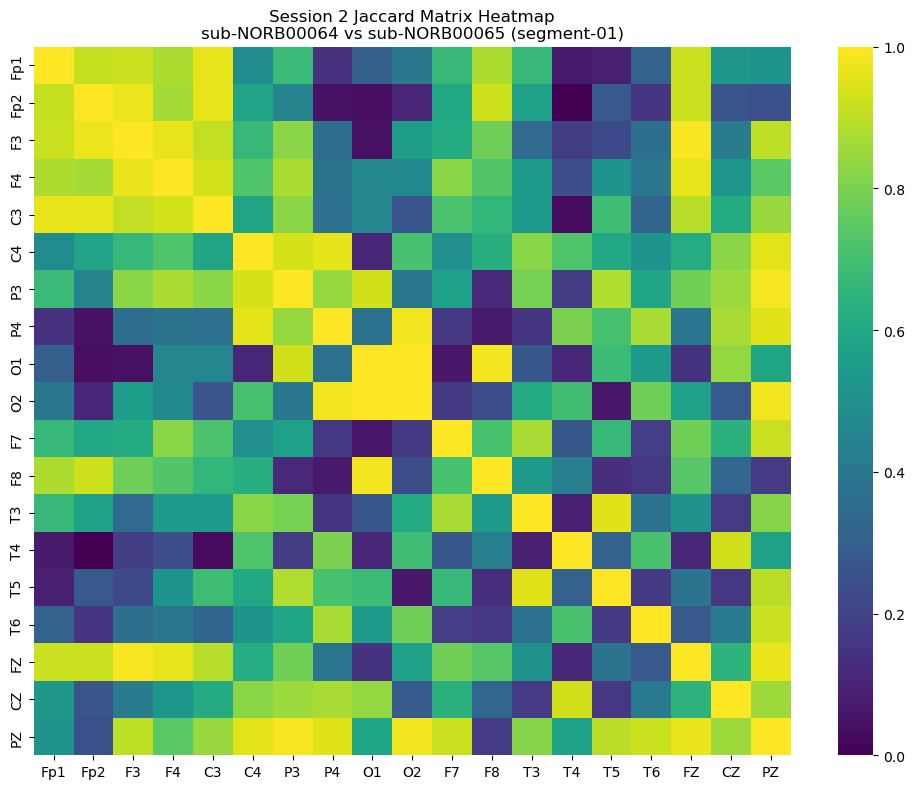

In [11]:
if jaccard_results_ses2:
    first_segment_ses2 = list(jaccard_results_ses2.keys())[0]
    if jaccard_results_ses2[first_segment_ses2]:
        sample_pair_ses2 = list(jaccard_results_ses2[first_segment_ses2].keys())[0]
        
        df_example_ses2 = jaccard_results_ses2[first_segment_ses2][sample_pair_ses2]
        
        print(f"Example Node-Pair Jaccard Matrix (Session 2)")
        print(f"Segment: {first_segment_ses2}")
        print(f"Subject Pair: {sample_pair_ses2[0]} and {sample_pair_ses2[1]}")
        
        display(df_example_ses2.head())
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(df_example_ses2, annot=False, cmap='viridis', vmin=0, vmax=1)
        plt.title(f"Session 2 Jaccard Matrix Heatmap\n{sample_pair_ses2[0]} vs {sample_pair_ses2[1]} ({first_segment_ses2})")
        plt.tight_layout()
        plt.show()
else:
    print("No Jaccard matrices found to display for Session 2.")

## Average Jaccard Matrices Across Segments for Session 2

Here we aggregate the Session 2 Jaccard matrices across all 20 segments for each subject pair.

Calculated average Jaccard matrix for 210 subject pairs in Session 2.

Example Averaged Jaccard Matrix for sub-NORB00064 and sub-NORB00065


,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T3,T4,T5,T6,FZ,CZ,PZ
Fp1,1.000000,0.927774,0.950724,0.770839,0.756955,0.600685,0.535225,0.532788,0.357458,0.502123,0.878892,0.799557,0.695908,0.378852,0.442184,0.396010,0.851523,0.707713,0.493998
Fp2,0.927774,1.000000,0.931447,0.873696,0.753770,0.708991,0.510101,0.530617,0.353890,0.515534,0.814054,0.889539,0.641592,0.499139,0.431219,0.469797,0.845135,0.618181,0.597041
F3,0.950724,0.931447,1.000000,0.943735,0.799248,0.789768,0.635963,0.557054,0.331445,0.457310,0.819926,0.853966,0.530676,0.556462,0.368008,0.524649,0.962967,0.725270,0.668845
F4,0.770839,0.873696,0.943735,1.000000,0.817017,0.837795,0.611632,0.634426,0.468957,0.553810,0.762026,0.838544,0.542719,0.666806,0.414317,0.545984,0.955138,0.730033,0.716902
C3,0.756955,0.753770,0.799248,0.817017,1.000000,0.767722,0.669697,0.651263,0.535866,0.476956,0.852853,0.692487,0.664301,0.596786,0.594835,0.462425,0.750158,0.789809,0.744595


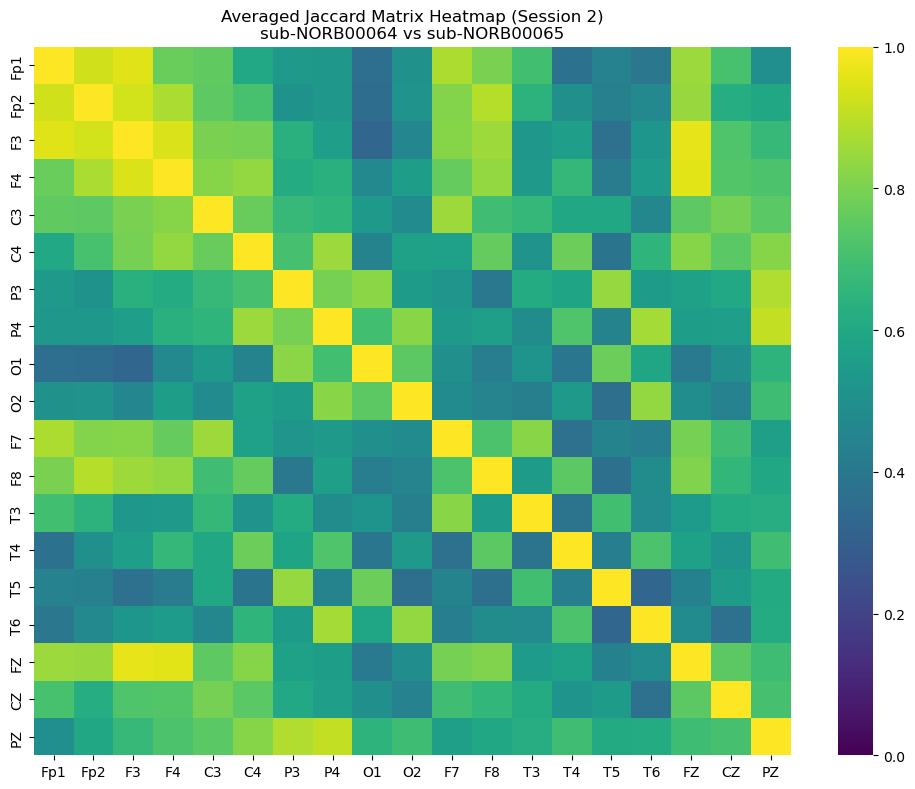

In [12]:
average_jaccard_results_ses2 = {}

if jaccard_results_ses2 and segment_keys_ses2[0] in jaccard_results_ses2:
    subject_pairs_ses2 = list(jaccard_results_ses2[segment_keys_ses2[0]].keys())
    
    for pair in subject_pairs_ses2:
        matrices_for_pair = []
        for segment in segment_keys_ses2:
            if segment in jaccard_results_ses2 and pair in jaccard_results_ses2[segment]:
                matrices_for_pair.append(jaccard_results_ses2[segment][pair])
        
        if matrices_for_pair:
            sum_matrix = sum(matrices_for_pair)
            avg_matrix = sum_matrix / len(matrices_for_pair)
            average_jaccard_results_ses2[pair] = avg_matrix

    print(f"Calculated average Jaccard matrix for {len(average_jaccard_results_ses2)} subject pairs in Session 2.")
    
    if average_jaccard_results_ses2:
        sample_pair_ses2 = subject_pairs_ses2[0]
        print(f"\nExample Averaged Jaccard Matrix for {sample_pair_ses2[0]} and {sample_pair_ses2[1]}")
        df_avg_example_ses2 = average_jaccard_results_ses2[sample_pair_ses2]
        display(df_avg_example_ses2.head())
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(df_avg_example_ses2, annot=False, cmap='viridis', vmin=0, vmax=1)
        plt.title(f"Averaged Jaccard Matrix Heatmap (Session 2)\n{sample_pair_ses2[0]} vs {sample_pair_ses2[1]}")
        plt.tight_layout()
        plt.show()
else:
    print("No Jaccard results found to average for Session 2.")

## Comprehensive Heatmap for All Subject Pairs (Session 2)

Finally, we plot the massive heatmap for `ses-2`, grouping edge pairs by band regions, and sorting subject pairs by their age differences for `ses-2`.


Session 2 Heatmap shape: (210, 171)
Valid subject pairs used: 210


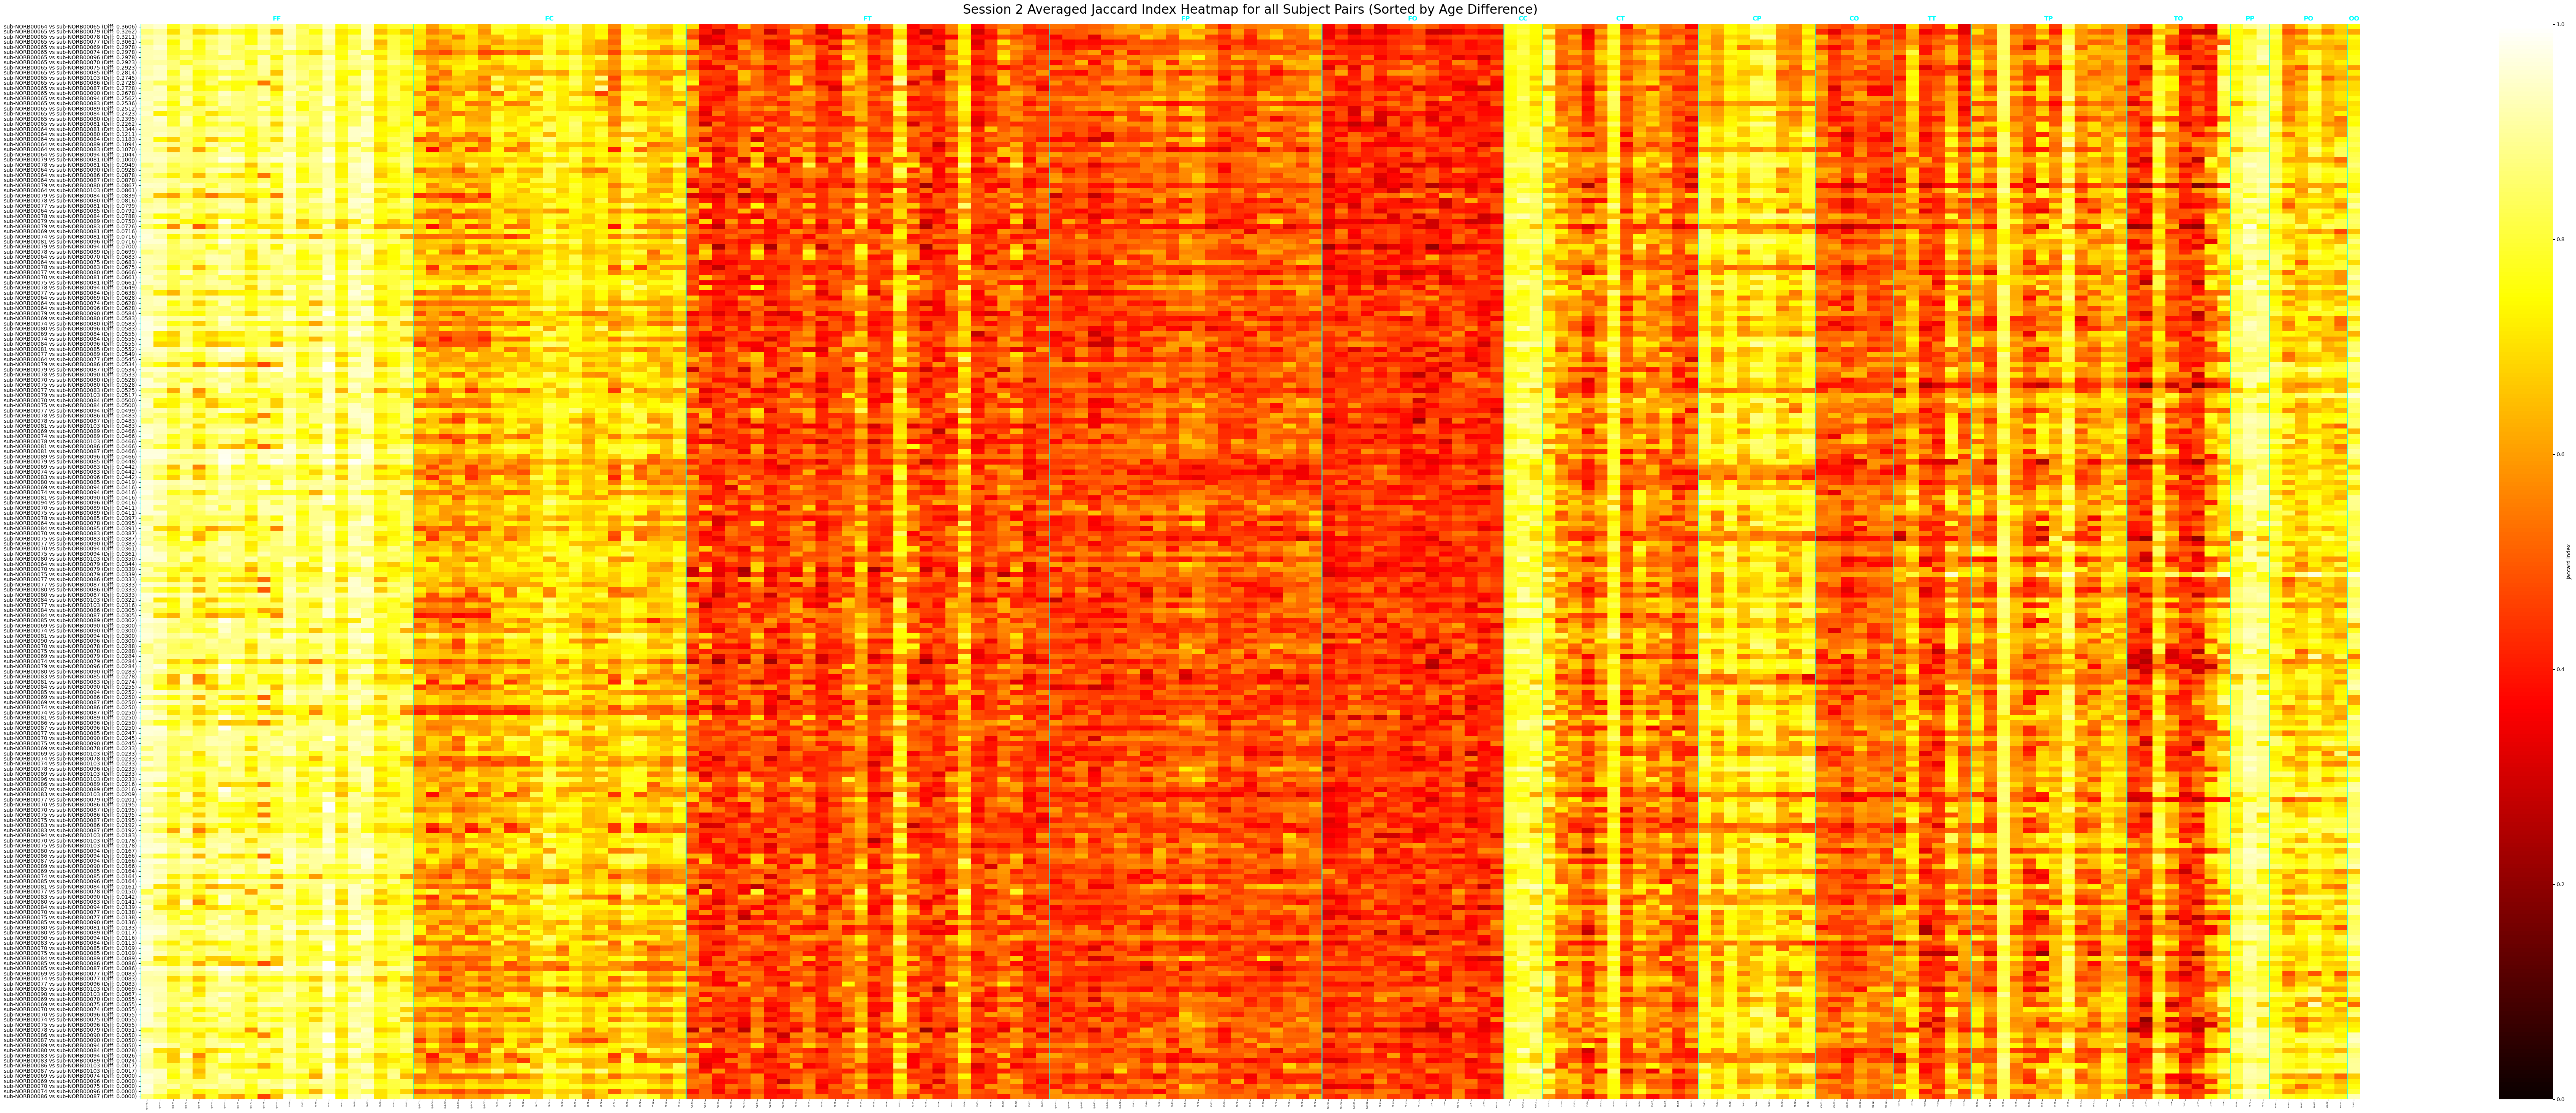

In [13]:
if average_jaccard_results_ses2:
    first_avg_mat_ses2 = list(average_jaccard_results_ses2.values())[0]
    nodes_ses2 = list(first_avg_mat_ses2.columns)
    edge_pairs_ses2 = list(itertools.combinations(nodes_ses2, 2))
    
    # Sort edge pairs by the same band logic used in Session 1
    sorted_edge_pairs_ses2 = sorted(edge_pairs_ses2, key=lambda ep: order_map[band_key(ep)])
    edge_labels_ses2 = [f"{a}-{b}" for a, b in sorted_edge_pairs_ses2]
    
    heatmap_rows_ses2 = []
    heatmap_indices_ses2 = []
    
    # Sort subject pairs by age difference (Session 2 ages)
    pair_age_diffs_ses2 = []
    for pair in average_jaccard_results_ses2.keys():
        sub1_label = f"{pair[0]}_ses-2"
        sub2_label = f"{pair[1]}_ses-2"
        
        if sub1_label in age_lookup and sub2_label in age_lookup:
            age_diff = abs(age_lookup[sub1_label] - age_lookup[sub2_label])
        else:
            age_diff = float('inf')
            
        pair_age_diffs_ses2.append({'pair': pair, 'age_diff': age_diff})
        
    # Sort descending so least age difference is at the bottom
    sorted_pair_dicts_ses2 = sorted(pair_age_diffs_ses2, key=lambda x: x['age_diff'], reverse=True)
    
    for pair_dict in sorted_pair_dicts_ses2:
        pair = pair_dict['pair']
        age_diff = pair_dict['age_diff']
        avg_mat = average_jaccard_results_ses2[pair]
        
        row_values = []
        for a, b in sorted_edge_pairs_ses2:
            if a in avg_mat.index and b in avg_mat.columns:
                row_values.append(avg_mat.loc[a, b])
            else:
                row_values.append(np.nan)
                
        heatmap_rows_ses2.append(row_values)
        if age_diff != float('inf'):
            heatmap_indices_ses2.append(f"{pair[0]} vs {pair[1]} (Diff: {age_diff:.4f})")
        else:
            heatmap_indices_ses2.append(f"{pair[0]} vs {pair[1]}")
            
    heatmap_df_ses2 = pd.DataFrame(
        heatmap_rows_ses2,
        index=heatmap_indices_ses2,
        columns=edge_labels_ses2
    )
    
    print(f"\nSession 2 Heatmap shape: {heatmap_df_ses2.shape}")
    print(f"Valid subject pairs used: {len(heatmap_df_ses2)}")
    
    if not heatmap_df_ses2.empty:
        fig_width = max(72, len(heatmap_df_ses2.columns) * 0.45)
        fig_height = max(18, len(heatmap_df_ses2.index) * 0.14)
        
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))
        sns.heatmap(
            heatmap_df_ses2,
            cmap='hot',
            cbar_kws={'label': 'Jaccard Index'},
            vmin=0,
            vmax=1,
            ax=ax,
            xticklabels=False,
            yticklabels=True,
        )
        
        ax.set_xticks(np.arange(len(heatmap_df_ses2.columns)) + 0.5)
        ax.set_xticklabels(heatmap_df_ses2.columns, rotation=90, fontsize=4)
        ax.tick_params(axis='x', which='both', length=2, pad=1)
        
        col_band_keys = [band_key(ep) for ep in sorted_edge_pairs_ses2]
        unique_band_keys = [k for k in order_keys if k in col_band_keys]
        
        for key in unique_band_keys:
            indices = [i for i, k in enumerate(col_band_keys) if k == key]
            if indices:
                start_idx = indices[0]
                ax.axvline(x=start_idx, color='cyan', linestyle='-', linewidth=2, alpha=0.7)
                ax.text(start_idx + len(indices)/2, -0.5, key, 
                        ha='center', va='bottom', color='cyan', fontsize=12, fontweight='bold')
        
        plt.title("Session 2 Averaged Jaccard Index Heatmap for all Subject Pairs (Sorted by Age Difference)", fontsize=24, pad=20)
        plt.tight_layout()
        plt.show()
else:
    print("No averaged Jaccard matrices available to plot for Session 2.")